# Exercise 5: Sampling the Hydrogen atom electron orbital
>***goal**: use the Metropolis algorithm to sample the probability distribution for the Hydrogen atom's electron in two different states:
> - the $(n, l, m) = (1, 0, 0)$ ground state
> $$ \big|\Psi_{(1, 0, 0)}(r, \theta, \phi)\big| = \mathcal{N}_{(1, 0, 0)} \, e^{-2r} $$
> - the $(n, l, m) = (2, 1, 0)$ excited state
> $$ \big| \Psi_{(2, 1, 0)}(r, \theta, \phi) \big| = \mathcal{N}_{(2, 1, 0)} \, z^2 e^{-r} $$

We first generate the data by sampling the distributions.
Note that the values chosen for `delta` are state-dependent, and were chosen (*manually*) so that the acceptance ratio would be close (within a few percent) to $r \simeq 0.5$.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import subprocess
import io

def hydrogen_gs(N):
    output = subprocess.run(["./run", str(N), "hydrogen", str(1), str(0), str(0), str(1.14)], 
                            cwd="./rannyu_rng",
                            capture_output=True,
                            text=True,
                            check=True)
    return np.array([ list(map(float, line.split(','))) for line in output.stdout.strip().split('\n') ])

def hydrogen_exc(N):
    output = subprocess.run(["./run", str(N), "hydrogen", str(2), str(1), str(0), str(2.8)], 
                            cwd="./rannyu_rng",
                            capture_output=True,
                            text=True,
                            check=True)
    return np.array([ list(map(float, line.split(','))) for line in output.stdout.strip().split('\n') ])

Nsmp_tot = int(1e6)
data_gs = hydrogen_gs(Nsmp_tot)
data_exc = hydrogen_exc(Nsmp_tot)

We can visualize the points in 3D space

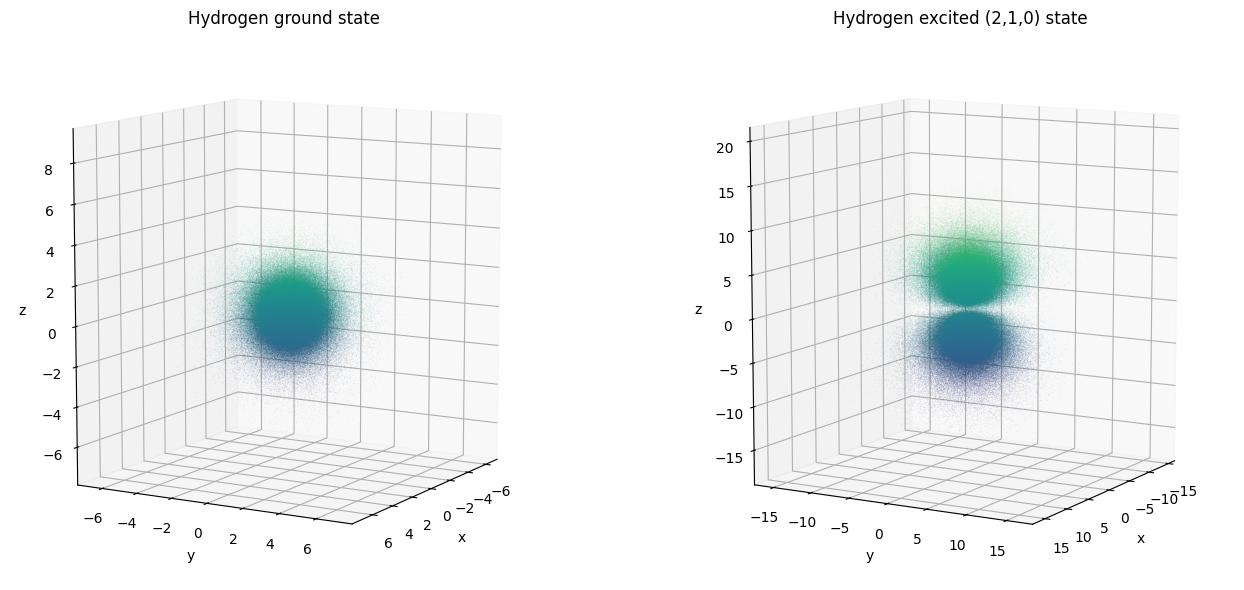

In [ ]:
def plot_orbital(fig, data, position, title):
    ax = fig.add_subplot(1, 2, position, projection='3d')
    ax.scatter(data[:, 0], data[:, 1], data[:, 2],
                c=data[:, 2], 
                cmap='viridis',
                marker='.', 
                s=1,
                alpha=0.15,
                linewidth=0
                )
    ax.set_box_aspect((
        np.ptp(data[:, 0]),
        np.ptp(data[:, 1]),
        np.ptp(data[:, 2])
    ))
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('z')
    ax.set_title(title)
    ax.view_init(elev=10, azim=30)

fig = plt.figure(figsize=(14, 6))
plot_orbital(fig, data_gs, 1, "Hydrogen ground state")
plot_orbital(fig, data_exc, 2, "Hydrogen excited (2,1,0) state")
plt.tight_layout()
plt.show()

Then plot the error as a function of *block width* (for a fixed $N_\text{total samples}$ value), so we can choose the correct block size:

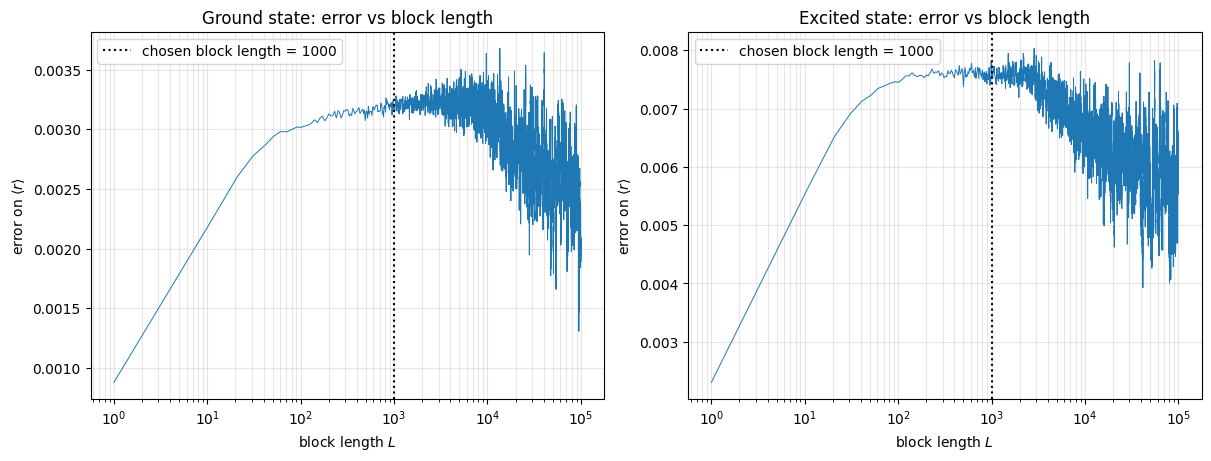

In [174]:
def error(av, av2, N):
    return np.sqrt((av2 - av*av)/max(1, N - 1))

def block_avgs(data, Nsmp):
    Nblk = data.size // Nsmp
    data = data[:Nsmp*Nblk]

    blk_data = data.reshape(Nblk, Nsmp)
    return np.mean(blk_data, axis=1)

def avg_err(data, Nsmp):
    blk_avg = block_avgs(data, Nsmp)

    avg = np.mean(blk_avg)
    avg2 = np.mean(blk_avg**2)
    err = error(avg, avg2, blk_avg.size)
    
    return avg, err

r_data_gs = np.linalg.norm(data_gs, axis=1)
r_data_exc = np.linalg.norm(data_exc, axis=1)
Nsmp_range = np.arange(1, int(1e5), 10) # check when the error estimate reaches a plateau

r_avg_gs = np.zeros(len(Nsmp_range))
r_err_gs = np.zeros(len(Nsmp_range))
for i, nsmp in enumerate(Nsmp_range):
    r_avg_gs[i], r_err_gs[i] = avg_err(r_data_gs, nsmp)
r_avg_exc = np.zeros(len(Nsmp_range))
r_err_exc = np.zeros(len(Nsmp_range))
for i, nsmp in enumerate(Nsmp_range):
    r_avg_exc[i], r_err_exc[i] = avg_err(r_data_exc, nsmp)

fig, axs = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for ax, err, state in [(axs[0], r_err_gs, "Ground state"), (axs[1], r_err_exc, "Excited state")]:
    ax.plot(Nsmp_range, err, lw=0.7)
    ax.axvline(Nsmp, color="k", ls=":", label=f"chosen block length = {Nsmp}")
    ax.set_xscale("log")
    ax.set_xlabel("block length $L$")
    ax.set_ylabel(r"error on $\langle r \rangle$")
    ax.set_title(f"{state}: error vs block length")
    ax.grid(alpha=0.3, which="both")
    ax.legend()

 Seeing that in both cases the error plateaus at around $10^3$ steps per block, that's the block size we'll use.
 
 We can now then compute the progressive values of $\langle r \rangle$ and its error estimate:

In the ground state, the average value of r is 1.6576, with an error estimate of 0.0032
In the (2,1,0) excited state, the average value of r is 5.2791, with an error estimate of 0.0076


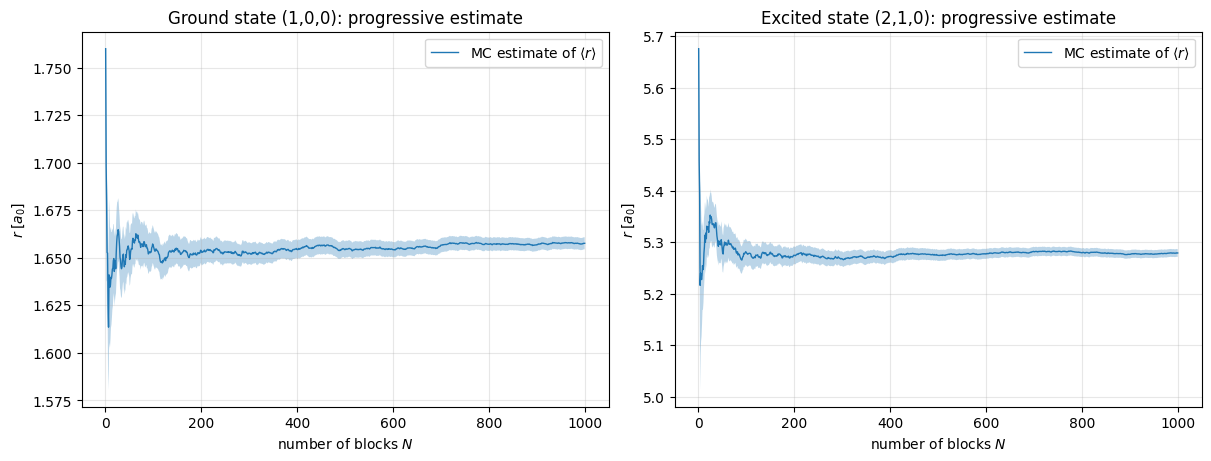

In [176]:
def progr_avg_err(data, Nsmp):
    blk_avgs = block_avgs(data, Nsmp)
    Nblk = blk_avgs.size
    progr_avg = np.zeros(Nblk)
    progr_avg2 = np.zeros(Nblk)
    progr_err = np.zeros(Nblk)
    for i, avg in enumerate(blk_avgs):
        for j in range(Nblk - i):
            progr_avg[i + j] += avg
            progr_avg2[i + j] += avg * avg
        progr_avg[i] /= i + 1
        progr_avg2[i] /= i + 1
        progr_err[i] = error(progr_avg[i], progr_avg2[i], i+1)
    
    return progr_avg, progr_err

Nsmp = int(1e3)
r_progr_avg_gs, r_progr_err_gs = progr_avg_err(r_data_gs, Nsmp)
r_progr_avg_exc, r_progr_err_exc = progr_avg_err(r_data_exc, Nsmp)

def plot_progressive(ax, avg, err, state):
    n = np.arange(1, avg.size + 1)
    ax.plot(n, avg, lw=1, label=r"MC estimate of $\langle r \rangle$")
    ax.fill_between(n, avg - err, avg + err, alpha=0.3)
    ax.set_xlabel("number of blocks $N$")
    ax.set_ylabel(r"$r\;[a_0]$")
    ax.set_title(f"{state}: progressive estimate")
    ax.grid(alpha=0.3)
    ax.legend()

fig, axs = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
plot_progressive(axs[0], r_progr_avg_gs,  r_progr_err_gs, "Ground state (1,0,0)")
plot_progressive(axs[1], r_progr_avg_exc, r_progr_err_exc, "Excited state (2,1,0)")

print(f"In the ground state, the average value of r is {r_progr_avg_gs[-1] :.4f}, with an error estimate of {r_progr_err_gs[-1] :.4f}")
print(f"In the (2,1,0) excited state, the average value of r is {r_progr_avg_exc[-1] :.4f}, with an error estimate of {r_progr_err_exc[-1] :.4f}")

Lastly we ca repeat everything we did with a different sampling method:
```cpp
void Random::hydrogen_nu(std::array<int, 3> quant_num, int N, double delta) {
  std::array<double, 3> pos{0, 0, 1}, pos_old = pos;
  double prob = hydrogen_prob_dist(quant_num, pos_old), prob_old = prob;

  int nacc = 0, natt = 0;
  for (int i = 0; i < N; i ++) {
    do {
      pos = pos_old;

      pos = {pos[0] + gauss(0.0, delta),
             pos[1] + gauss(0.0, delta), 
             pos[2] + gauss(0.0, delta)};
      prob = hydrogen_prob_dist(quant_num, pos);
      natt++;
    } while (rannyu() >= std::min(1.0, prob / prob_old));

    std::cout << pos[0] << "," << pos[1] << "," << pos[2] << "\n";
    nacc++;
    pos_old = pos;
    prob_old = prob;
  }
  std::cerr << "Acceptance ratio: " << double(nacc) / natt << std::endl;
}
```

which generates point sampling a Gaussian for each coordinate.

In the ground state, the average value of r is 1.6576, with an error estimate of 0.0032
In the (2,1,0) excited state, the average value of r is 5.2791, with an error estimate of 0.0076


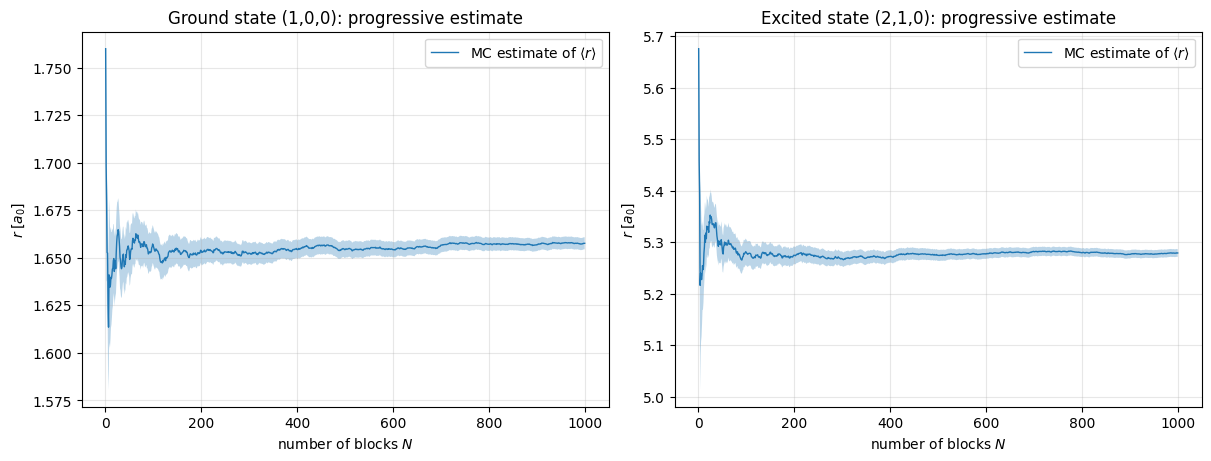

In [175]:
def hydrogen_gs_nu(N):
    output = subprocess.run(["./run", str(N), "hydrogen_nu", str(1), str(0), str(0), str(0.75)], 
                            cwd="./rannyu_rng",
                            capture_output=True,
                            text=True,
                            check=True)
    return np.array([ list(map(float, line.split(','))) for line in output.stdout.strip().split('\n') ])

def hydrogen_exc_nu(N):
    output = subprocess.run(["./run", str(N), "hydrogen_nu", str(2), str(1), str(0), str(1.85)], 
                            cwd="./rannyu_rng",
                            capture_output=True,
                            text=True,
                            check=True)
    return np.array([ list(map(float, line.split(','))) for line in output.stdout.strip().split('\n') ])

Nsmp_tot = int(1e6)
Nsmp = int(1e3)
data_gs = hydrogen_gs_nu(Nsmp_tot)
data_exc = hydrogen_exc_nu(Nsmp_tot)

r_data_gs = np.linalg.norm(data_gs, axis=1)
r_data_exc = np.linalg.norm(data_exc, axis=1)
r_progr_avg_gs, r_progr_err_gs = progr_avg_err(r_data_gs, Nsmp)
r_progr_avg_exc, r_progr_err_exc = progr_avg_err(r_data_exc, Nsmp)

fig, axs = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
plot_progressive(axs[0], r_progr_avg_gs,  r_progr_err_gs, "Ground state (1,0,0)")
plot_progressive(axs[1], r_progr_avg_exc, r_progr_err_exc, "Excited state (2,1,0)")

print(f"In the ground state, the average value of r is {r_progr_avg_gs[-1] :.4f}, with an error estimate of {r_progr_err_gs[-1] :.4f}")
print(f"In the (2,1,0) excited state, the average value of r is {r_progr_avg_exc[-1] :.4f}, with an error estimate of {r_progr_err_exc[-1] :.4f}")

Comparing the final results for both states, we can see that the two methods for sampling give compatible results and similar efficiency, given that we adjust the parameters to get a $\sim 50\%$ acceptance ratio.